<a href="https://colab.research.google.com/github/192565074simats-code/MLA0201/blob/main/Experiment_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

TRAINING DATASET


,Outlook,Temperature,Humidity,Wind,Play
0,Sunny,Hot,High,Weak,No
1,Sunny,Hot,High,Strong,No
2,Overcast,Hot,High,Weak,Yes
3,Rain,Mild,High,Weak,Yes
4,Rain,Cool,Normal,Weak,Yes
5,Rain,Cool,Normal,Strong,No
6,Overcast,Cool,Normal,Strong,Yes
7,Sunny,Mild,High,Weak,No
8,Sunny,Cool,Normal,Weak,Yes
9,Rain,Mild,Normal,Weak,Yes



MODEL: ID3 DECISION TREE
Training Accuracy: 100.0 %

NEW SAMPLE:


,Outlook,Temperature,Humidity,Wind
0,Sunny,Cool,High,Strong


PREDICTED CLASS: No


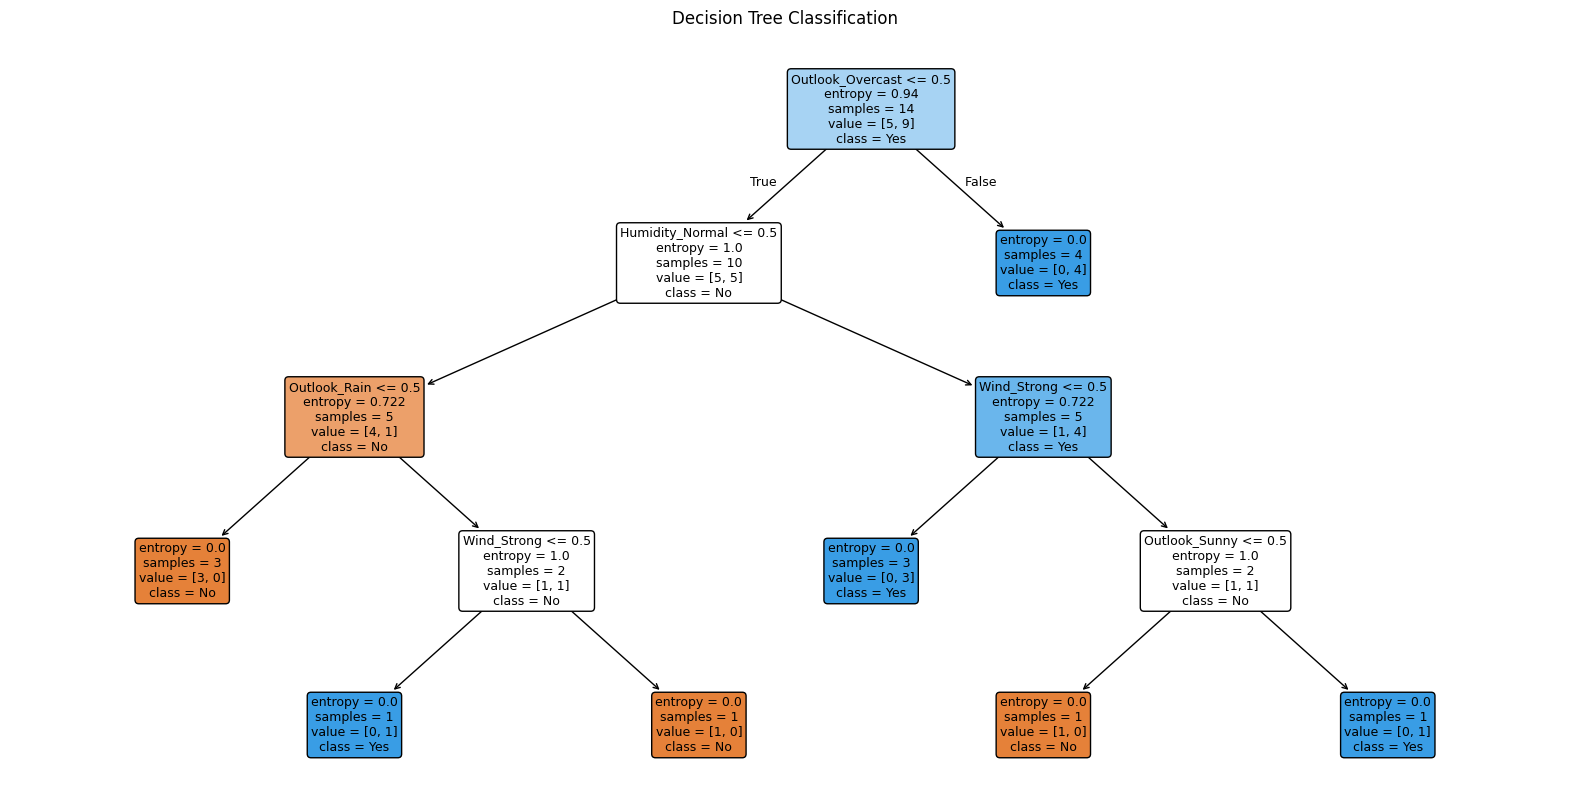

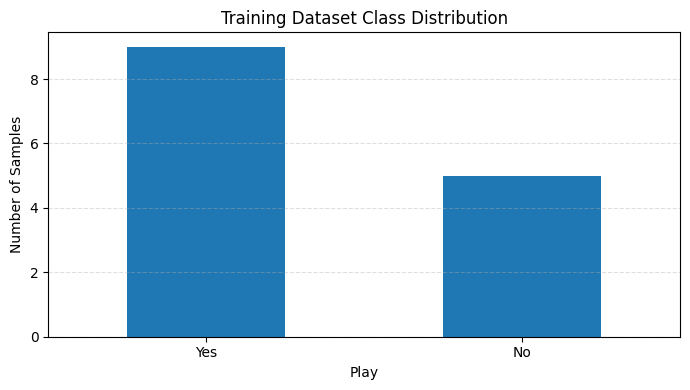

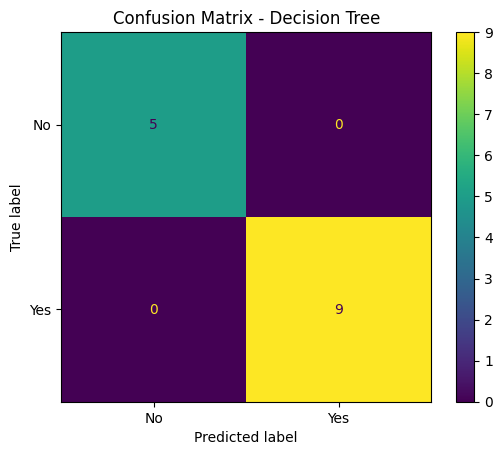

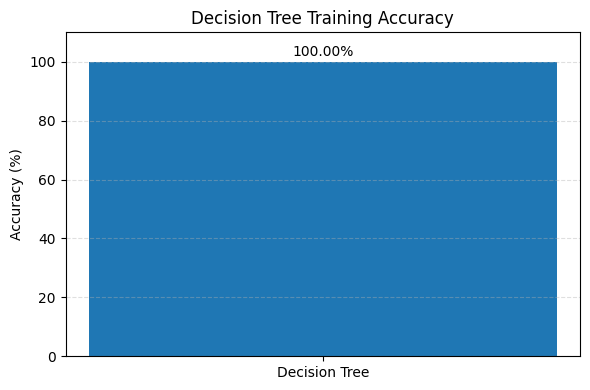

In [1]:
# EXPERIMENT 3: DECISION TREE USING ID3 ALGORITHM

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# 1. Create Training Dataset
data = {
    'Outlook': [
        'Sunny', 'Sunny', 'Overcast', 'Rain',
        'Rain', 'Rain', 'Overcast', 'Sunny',
        'Sunny', 'Rain', 'Sunny', 'Overcast',
        'Overcast', 'Rain'
    ],
    'Temperature': [
        'Hot', 'Hot', 'Hot', 'Mild',
        'Cool', 'Cool', 'Cool', 'Mild',
        'Cool', 'Mild', 'Mild', 'Mild',
        'Hot', 'Mild'
    ],
    'Humidity': [
        'High', 'High', 'High', 'High',
        'Normal', 'Normal', 'Normal', 'High',
        'Normal', 'Normal', 'Normal', 'High',
        'Normal', 'High'
    ],
    'Wind': [
        'Weak', 'Strong', 'Weak', 'Weak',
        'Weak', 'Strong', 'Strong', 'Weak',
        'Weak', 'Weak', 'Strong', 'Strong',
        'Weak', 'Strong'
    ],
    'Play': [
        'No', 'No', 'Yes', 'Yes',
        'Yes', 'No', 'Yes', 'No',
        'Yes', 'Yes', 'Yes', 'Yes',
        'Yes', 'No'
    ]
}

df = pd.DataFrame(data)

print("TRAINING DATASET")
display(df)

# 2. Encode Categorical Data
X = df.drop('Play', axis=1)
y = df['Play']

X_encoded = pd.get_dummies(X)

# 3. Build Decision Tree
model = DecisionTreeClassifier(
    criterion='entropy',
    random_state=42
)

model.fit(X_encoded, y)

# 4. Display Training Accuracy
predictions = model.predict(X_encoded)
accuracy = accuracy_score(y, predictions)

print("\nMODEL: ID3 DECISION TREE")
print("Training Accuracy:", round(accuracy * 100, 2), "%")

# 5. Predict a New Sample
new_sample = pd.DataFrame([{
    'Outlook': 'Sunny',
    'Temperature': 'Cool',
    'Humidity': 'High',
    'Wind': 'Strong'
}])

new_encoded = pd.get_dummies(new_sample)
new_encoded = new_encoded.reindex(
    columns=X_encoded.columns,
    fill_value=0
)

prediction = model.predict(new_encoded)

print("\nNEW SAMPLE:")
display(new_sample)

print("PREDICTED CLASS:", prediction[0])

# 6. Visualize Decision Tree
plt.figure(figsize=(20, 10))

plot_tree(
    model,
    feature_names=X_encoded.columns,
    class_names=model.classes_,
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Decision Tree Classification")
plt.show()

# 7. Matplotlib Bar Graph
plt.figure(figsize=(7, 4))

df['Play'].value_counts().reindex(
    ['Yes', 'No'], fill_value=0
).plot(kind='bar')

plt.title("Training Dataset Class Distribution")
plt.xlabel("Play")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

# 8. Confusion Matrix
cm = confusion_matrix(y, predictions, labels=['No', 'Yes'])

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No', 'Yes']
)

display_cm.plot()
plt.title("Confusion Matrix - Decision Tree")
plt.show()

# 9. Accuracy Bar Graph
plt.figure(figsize=(6, 4))

plt.bar(
    ['Decision Tree'],
    [accuracy * 100]
)

plt.title("Decision Tree Training Accuracy")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 110)

for i, value in enumerate([accuracy * 100]):
    plt.text(i, value + 2, f'{value:.2f}%', ha='center')

plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()